In [1]:
import glob
import os
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
# -------- Paramètres --------
data_dir = "/data1/data/obs/level3/DC_mapping_SWOT/karin"
date = "20240429"  # Date au format YYYYMMDD

In [3]:
# -------- Recherche des fichiers du jour --------
pattern = os.path.join(
    data_dir,
    f"SWOT_L3_LR_SSH_Expert_*_{date}T*.nc"
)
files = sorted(glob.glob(pattern))

print(f"{len(files)} fichiers trouvés pour le {date}")

28 fichiers trouvés pour le 20240429


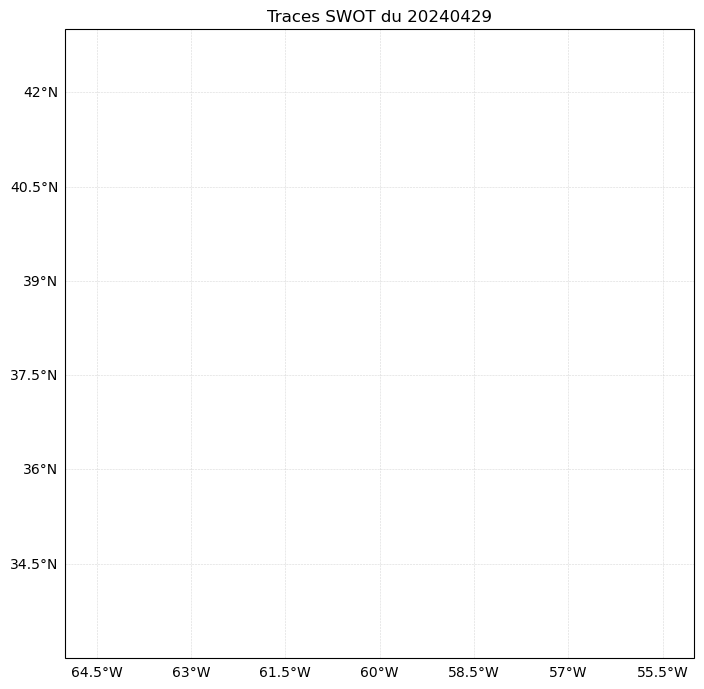

In [4]:
# Figure avec projection géographique
fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection=ccrs.PlateCarree())

# Fond de carte
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="white", zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5)

# Grille longitude / latitude
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    linestyle="--",
    alpha=0.5
)
gl.top_labels = False
gl.right_labels = False

# Traces SWOT
for file in files:
    with xr.open_dataset(file) as ds:
        lon = ds["longitude"].values
        lat = ds["latitude"].values

        ax.scatter(
            lon, lat,
            s=1,
            transform=ccrs.PlateCarree(),
            rasterized=True
        )

ax.set_title(f"Traces SWOT du {date}")

ax.set_extent([-65, -55, 33, 43],
                crs=ccrs.PlateCarree()) #zoom sur une région

plt.tight_layout()
plt.show()